# WellSense · Notebook 3 — Inference Engine, Diagnosis, Explanation and Decision Support
This notebook runs the knowledge-based system on **real Petrobras events** and shows every reasoning feature:

| Section | Feature |
|---|---|
| 1 | How the inference engine works (forward chaining, conflict resolution, certainty factors) |
| 2 | **Case A** — spurious DHSV closure: monitoring replay, reasoning trace, **HOW** and **WHY-NOT** explanations, maintenance advice |
| 3 | **Case B** — frozen downhole gauge: **conflicting evidence**, **incomplete information**, **backward chaining** (the KBS asks the operator), **WHAT-IF** |
| 4 | **Case C** — severe slugging: why pressure-location reasoning is switched off while flow oscillates |
| 5 | **Case D** — hydrate in production line: **safety constraints** block dangerous actions |
| 6 | **Case E** — no trustworthy sensors: the KBS says *"cannot decide"* instead of guessing |
| 7 | **Stakeholder trade-offs**: how the recommendation changes with Safety / Production / Cost priorities |
| 8 | **Knowledge refinement** on the development set (what was changed, and why) |
| 9 | **Live consultation prototype**: describe what you see → diagnosis, questions, explanation and safe, stakeholder-aware actions |

The engine is our own Python code in `wellsense/` — about 300 lines, no expert-system library — so every step can be explained.

## Setup
Set `INTERACTIVE = True` to answer the KBS's questions yourself in Case B (in Colab, an input box appears). The live consultation in Section 9 has its own clickable answer buttons and does not need this. With `False`, scripted operator answers are used.

In [1]:
SOURCE = 'drive'          # 'drive' or 'upload' (see Notebook 1)
INTERACTIVE = False

import os, sys, zipfile
try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
def find_project(root='/content/drive/MyDrive', max_depth=3):
    """Find the folder that contains both 'wellsense' (our code) and 'knowledge_base' (works even as 'WellSense (1)/WellSense')."""
    root_depth = root.rstrip('/').count('/')
    for path, dirs, files in os.walk(root):
        if path.count('/') - root_depth >= max_depth:
            dirs[:] = []
            continue
        if 'wellsense' in dirs and 'knowledge_base' in dirs:
            return path
    return None

if not IN_COLAB:
    PROJECT_DIR = os.getcwd()
elif SOURCE == 'drive':
    from google.colab import drive
    drive.mount('/content/drive')
    PROJECT_DIR = find_project()
    if PROJECT_DIR is None:
        raise FileNotFoundError("No folder with both 'wellsense' and 'knowledge_base' inside it was found in My Drive.")
else:
    from google.colab import files
    PROJECT_DIR = '/content/WellSense'
    if not os.path.exists(PROJECT_DIR):
        for name in files.upload():
            zipfile.ZipFile(name).extractall('/content')
print('Project folder:', PROJECT_DIR)
os.chdir(PROJECT_DIR)
sys.path.insert(0, PROJECT_DIR)
os.makedirs('outputs/figures', exist_ok=True); os.makedirs('outputs/tables', exist_ok=True)

import sqlite3, warnings, inspect
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from wellsense import KnowledgeBase, InferenceEngine, combine_cf, explain, decision, monitor, evaluate

warnings.filterwarnings('ignore')
pd.set_option('display.width', 220); pd.set_option('display.max_colwidth', 110); pd.set_option('display.max_rows', 80)
plt.rcParams.update({'figure.dpi': 100, 'axes.spines.top': False, 'axes.spines.right': False})

kb = KnowledgeBase('knowledge_base')
engine = InferenceEngine(kb)                     # keeps a full reasoning trace
con = sqlite3.connect('db/wellsense.db')
instances = pd.read_sql('SELECT * FROM instances', con).set_index('instance_id')
instances['labels_consistent'] = instances['labels_consistent'].astype(bool)
clean = lambda iid: pd.read_sql('SELECT * FROM clean_observations WHERE instance_id=? ORDER BY timestamp', con, params=(iid,))
facts_of = lambda iid: pd.read_sql('SELECT * FROM facts WHERE instance_id=? ORDER BY timestamp', con, params=(iid,))
FAULTS = list(kb.faults); LABEL = {f: kb.faults[f]['label'] for f in FAULTS}
VARS = monitor.ANALOG
S = kb.settings
print(f"Alarm when CF ≥ {S['alarm_threshold']} for {S['alarm_persistence_min']} minutes; ask questions when CF ≥ {S['ask_threshold']}")

Project folder: /content/drive/MyDrive/WellSense
Alarm when CF ≥ 0.6 for 5 minutes; ask questions when CF ≥ 0.3


---
## 1. How the inference engine works
**Working memory** holds facts as *(fact, value) → certainty factor*. Sensor facts enter with CF = the reading's trust (1.0 good, 0.8 filled-in, 0.2 frozen; missing readings do not enter at all).

**Forward chaining (data-driven)** — repeated recognise–act cycles:
1. **Match:** find every rule whose conditions hold (a condition holds when its fact has CF ≥ 0.2; a *NOT* condition holds when the fact is *not* believed — negation as failure).
2. **Conflict resolution:** from all matching rules (the *conflict set* / agenda), pick ONE by (a) highest **salience** — data abstractions before locations before diagnoses before meta-rules; (b) **specificity** — more conditions first; (c) **strength** — larger |CF| first. **Refractoriness:** a rule fires at most once.
3. **Act:** conclusion CF = rule CF × min(condition CFs); if the fact already has a CF, combine them with the MYCIN formula.

**Backward chaining (goal-driven)** — when the best hypothesis is uncertain (0.3 ≤ CF < 0.8), the engine takes it as a *goal*, looks for rules that could confirm or reject it using a fact only a person can provide, and asks that question.

In [2]:
print(inspect.getsource(combine_cf))
for a, b in [(0.6, 0.5), (0.85, 0.4), (0.7, -0.4), (-0.5, -0.5)]:
    print(f'combine({a:+.2f}, {b:+.2f}) = {combine_cf(a, b):+.3f}')

def combine_cf(a, b):
    """Combine two certainty factors for the same conclusion (MYCIN)."""
    if a >= 0 and b >= 0:
        return a + b * (1 - a)
    if a < 0 and b < 0:
        return a + b * (1 + a)
    return (a + b) / (1 - min(abs(a), abs(b)))

combine(+0.60, +0.50) = +0.800
combine(+0.85, +0.40) = +0.910
combine(+0.70, -0.40) = +0.500
combine(-0.50, -0.50) = -0.750


In [3]:
print(inspect.getsource(InferenceEngine.forward_chain))

    def forward_chain(self, wm, max_cycles=500):
        cycle = len(wm.trace)
        while cycle < max_cycles:
            agenda = []
            for r in self.rules:
                if r.id in wm.fired:
                    continue
                m = self.match(r, wm)
                if m:
                    agenda.append((r, m))
            if not agenda:
                break
            # Conflict resolution: 1) salience  2) specificity (more conditions)  3) stronger rule CF
            r, (cf_in, used) = max(agenda, key=lambda a: (a[0].salience, len(a[0].conditions), abs(a[0].cf)))
            wm.fired.add(r.id)
            contribution = r.cf * cf_in
            key = (r.fact, r.value)
            old = wm.facts.get(key)
            new = contribution if old is None else combine_cf(old, contribution)
            wm.facts[key] = new
            wm.origin.setdefault(key, 'inferred')
            wm.present.add(r.fact)
            f = Firing(cycle, r.id, used, round(cf_in, 3), r

---
## 2. Case A — spurious closure of the downhole safety valve
A real event on WELL-00003. The KBS replays the well minute by minute, exactly as it would run in a control room.

Petrobras fault onset: minute 204   ·   WellSense DHSV alarm: minute 209 (5 min after onset)


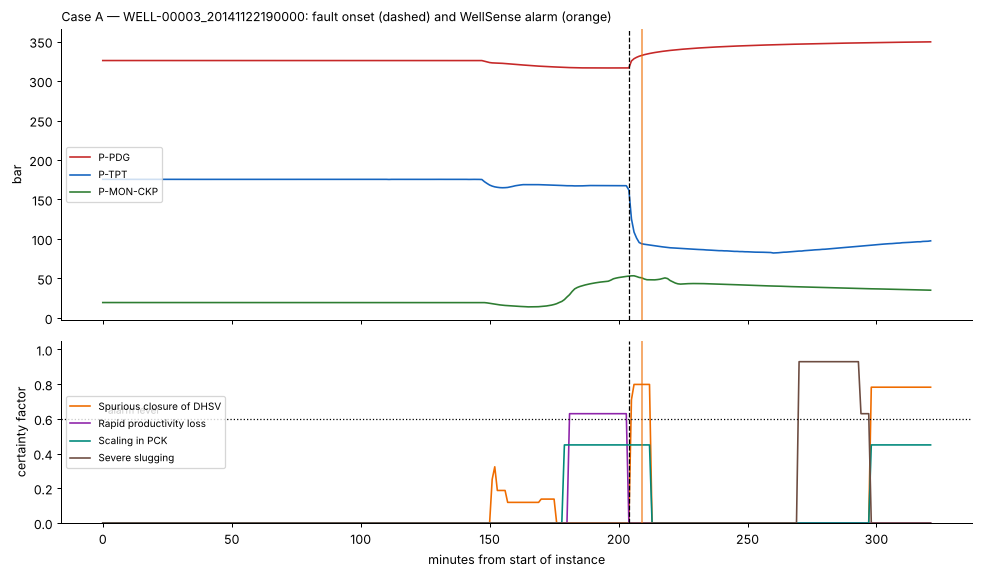

In [4]:
A = 'WELL-00003_20141122190000'
fa, ca = facts_of(A), clean(A)
tl = monitor.replay(engine, fa)
al = monitor.alarms(tl, FAULTS, S['alarm_threshold'], S['alarm_persistence_min'])
onset = instances.loc[A, 'onset_minute']
first_dhsv = int(tl.loc[al['SPURIOUS_CLOSURE_OF_DHSV'], 'minute'].iloc[0])
print(f'Petrobras fault onset: minute {onset:.0f}   ·   WellSense DHSV alarm: minute {first_dhsv} '
      f'({first_dhsv - onset:.0f} min after onset)')

fig, axes = plt.subplots(2, 1, figsize=(11, 6.5), sharex=True, gridspec_kw={'height_ratios': [1.6, 1]})
for v, c in [('p_pdg', '#c62828'), ('p_tpt', '#1565c0'), ('p_mon_ckp', '#2e7d32')]:
    axes[0].plot(ca[v], color=c, lw=1.3, label=v.upper().replace('_', '-'))
axes[0].set_ylabel('bar'); axes[0].legend(loc='center left', fontsize=8)
for f, c in [('SPURIOUS_CLOSURE_OF_DHSV', '#ef6c00'), ('RAPID_PRODUCTIVITY_LOSS', '#8e24aa'), ('SCALING_IN_PCK', '#00897b'), ('SEVERE_SLUGGING', '#6d4c41')]:
    axes[1].plot(tl['minute'], tl[f], color=c, lw=1.3, label=LABEL[f])
axes[1].axhline(S['alarm_threshold'], color='k', ls=':', lw=1); axes[1].text(2, S['alarm_threshold'] + 0.03, 'alarm level', fontsize=8)
axes[1].set_ylabel('certainty factor'); axes[1].set_ylim(0, 1.05); axes[1].legend(loc='center left', fontsize=8)
for ax in axes:
    ax.axvline(onset, color='k', ls='--', lw=1)
    ax.axvline(first_dhsv, color='#ef6c00', ls='-', lw=1.5, alpha=0.6)
axes[0].set_title(f'Case A — {A}: fault onset (dashed) and WellSense alarm (orange)', loc='left', fontsize=10)
axes[1].set_xlabel('minutes from start of instance')
plt.tight_layout(); plt.savefig('outputs/figures/20_caseA_replay.png', dpi=150); plt.show()

### 2.1 The reasoning trace at the alarm minute
Every rule that fired, in firing order. *Agenda* = how many rules competed in that cycle (the conflict set); conflict resolution picked one each time.

In [5]:
rowA = fa.iloc[first_dhsv].to_dict()
wmA = engine.forward_chain(engine.initial_memory(rowA, VARS))
trace = pd.DataFrame([{'cycle': f.cycle, 'agenda (conflict set)': f.agenda_size, 'rule fired': f.rule_id,
                       'level': kb.rule_by_id[f.rule_id].level, 'salience': kb.rule_by_id[f.rule_id].salience,
                       'conclusion': f'{kb.rule_by_id[f.rule_id].fact} = {kb.rule_by_id[f.rule_id].value}',
                       'premise CF': f.cf_in, 'contribution': f.contribution, 'CF after': f.result} for f in wmA.trace])
trace

,cycle,agenda (conflict set),rule fired,level,salience,conclusion,premise CF,contribution,CF after
0,0,14,A-PDG_P-2,symptom,90,PDG_P = UP,1.000,0.700,0.700
1,1,13,A-TPT_P-4,symptom,90,TPT_P = DOWN,1.000,0.700,0.700
2,2,13,A-CKP_P-2,symptom,90,CKP_P = UP,1.000,0.700,0.700
3,3,12,A-TPT_T-4,symptom,90,TPT_T = DOWN,1.000,0.700,0.700
4,4,12,A-ANN_P-4,symptom,90,ANN_P = DOWN,1.000,0.700,0.700
5,5,12,A-PDG_P-1,symptom,90,PDG_P = UP,1.000,0.900,0.970
6,6,11,A-TPT_P-3,symptom,90,TPT_P = DOWN,1.000,0.900,0.970
7,7,10,A-CKP_P-1,symptom,90,CKP_P = UP,1.000,0.900,0.970
8,8,9,A-TPT_T-3,symptom,90,TPT_T = DOWN,1.000,0.900,0.970
9,9,8,A-ANN_P-3,symptom,90,ANN_P = DOWN,1.000,0.900,0.970


In [6]:
print('Diagnoses:', [(LABEL[f], round(c, 2)) for f, c in engine.diagnoses(wmA)])
print('Verdict:', engine.verdict(wmA))

Diagnoses: [('Spurious closure of DHSV', 0.8), ('Scaling in PCK', 0.45)]
Verdict: ('SPURIOUS_CLOSURE_OF_DHSV', 0.7986388299999999)


### 2.2 HOW did the KBS reach this conclusion?

In [7]:
print('\n'.join(explain.how(engine, wmA, 'FAULT', 'SPURIOUS_CLOSURE_OF_DHSV')))

Spurious closure of DHSV: CF +0.80
  ← rule D-DHSV-1 "Spurious DHSV closure (restriction at DHSV + flow stopping)" (rule CF +0.85 × premise 0.68 = +0.58)
     because: A blockage at the DHSV with production stopping is the signature of a spurious DHSV closure.
        RESTRICTION = DHSV_ZONE: CF +0.87
          ← rule L-DHSV-1 "Restriction between downhole gauge and subsea tree" (rule CF +0.90 × premise 0.97 = +0.87)
             because: Pressure rises below and falls above the DHSV: something is blocking flow between the PDG and the TPT — where the DHSV sits.
                PDG_P = UP: CF +0.97
                  ← rule A-PDG_P-2 "Downhole pressure (PDG) rising" (rule CF +0.70 × premise 1.00 = +0.70)
                     because: Downhole pressure (PDG) rose more than the normal 15-minute variation (and is not below normal — a low but recovering reading is not 'up').
                        • sensor fact p_pdg.trend = RISING (trust 1.00, reading quality OK)
                  ← rule A

### 2.3 WHY NOT a hydrate in the production line?
Both faults stop the flow, so it is a natural alternative. The explanation shows exactly which condition rules it out.

In [8]:
print('\n'.join(explain.why_not(engine, wmA, 'HYDRATE_IN_PRODUCTION_LINE')))

Why not 'Hydrate in production line'?  (current CF +0.00)
  D-HPL-1 [did not fire] Hydrate in production line (restriction in line + flow stopping)
      ✗ needs RESTRICTION = PRODUCTION_LINE; have {'DHSV_ZONE': 0.87}
  D-HPL-2 [did not fire] Hydrate in production line (restriction in line)
      ✗ needs RESTRICTION = PRODUCTION_LINE; have {'DHSV_ZONE': 0.87}
  D-HPL-3 [did not fire] Hydrate in production line (hydrate conditions + restriction)
      ✗ needs RESTRICTION = PRODUCTION_LINE; have {'DHSV_ZONE': 0.87}
      ✗ needs HYDRATE_CONDITIONS = YES; have nothing (unknown)
  D-HPL-4 [did not fire] Hydrate in production line (deep pressure up, tree cooling)
      ✗ TPT_P IS DOWN (CF 0.97) but the rule needs it NOT to be


### 2.4 Maintenance recommendation (Safety-first profile)

In [9]:
decision.recommend(kb, 'SPURIOUS_CLOSURE_OF_DHSV', 'SAFETY_FIRST', wm=wmA)

,rank,id,action,for,safety_risk,production_loss,cost,effectiveness,score,status,why
0,1,A-DHSV-1,"Equalize pressure across the DHSV, then reopen it through its hydraulic control line (corrective operating...",fault,2,1,1,5,0.850,allowed,Restores production quickly without a rig; the thesis notes timely detection allows reopening by correctiv...
1,2,A-DHSV-2,Keep the well closed and schedule a DHSV inspection / workover.,fault,1,5,5,4,0.787,allowed,Safest for the well barrier but loses production for days and may need a rig (> US$500k/day).
2,<NA>,A-DHSV-3,Force the DHSV open by raising control-line pressure without equalizing.,fault,5,1,1,3,NaN,BLOCKED by SC-DHSV-EQUALIZE,"Never force a closed DHSV open against a pressure difference — equalize pressure across the valve first, t..."


---
## 3. Case B — frozen gauge, conflicting evidence and backward chaining
Another DHSV closure, on WELL-00011 — but here the **downhole gauge (PDG) is frozen**: it reports exactly 386.0 bar for hours.
* The frozen reading conflicts with the live subsea sensor. The KBS raises a **sensor alert**, gives the PDG trust 0.2, and reasons with the reliable sensors instead (the thesis rates TPT as reliable and notes PDGs often fail).
* Without the PDG, the data can only partly support the diagnosis — CF stays **below the alarm level**. This is **incomplete information**.
* So the KBS switches to **backward chaining**: it takes "DHSV closure" as a goal and **asks the operator** the questions that can confirm or reject it.

In [10]:
B = 'WELL-00011_20140726165720'
fb = facts_of(B)
onsetB = int(instances.loc[B, 'onset_minute'])
tlB = monitor.replay(engine, fb)
suspect = int(tlB.loc[(tlB['minute'] > onsetB) & (tlB['SPURIOUS_CLOSURE_OF_DHSV'] >= S['ask_threshold']), 'minute'].iloc[0])
rowB = fb.iloc[suspect].to_dict()
print(f'Fault onset minute {onsetB}; first suspicion at minute {suspect}')
print('Reading quality now:', {v: rowB[f'{v}_q'] for v in ['p_pdg', 'p_tpt', 't_tpt', 'p_mon_ckp']})
wmB = engine.forward_chain(engine.initial_memory(rowB, VARS))
print('Sensor alerts:', [v for (f, v), c in wmB.facts.items() if f == 'SENSOR_ALERT'])
print('Data-only diagnoses:', [(LABEL[f], round(c, 2)) for f, c in engine.diagnoses(wmB)], '→ below alarm level', S['alarm_threshold'])

Fault onset minute 79; first suspicion at minute 85
Reading quality now: {'p_pdg': 'FROZEN', 'p_tpt': 'OK', 't_tpt': 'OK', 'p_mon_ckp': 'NOT_INSTALLED'}
Sensor alerts: ['PDG_FROZEN']
Data-only diagnoses: [('Spurious closure of DHSV', 0.47)] → below alarm level 0.6


In [11]:
print('\n'.join(explain.how(engine, wmB, 'SENSOR_ALERT', 'PDG_FROZEN')))
print()
print('\n'.join(explain.how(engine, wmB, 'FAULT', 'SPURIOUS_CLOSURE_OF_DHSV')))

SENSOR_ALERT = PDG_FROZEN: CF +0.70
  ← rule V-PDG-FROZEN "Downhole gauge frozen while subsea pressure changes" (rule CF +1.00 × premise 0.70 = +0.70)
     because: P-PDG has reported exactly the same value for over an hour while the reliable TPT sensor shows a real change. The two disagree; the thesis notes PDGs commonly freeze or fail, while TPT is considered reliable, so PDG is discounted (trust 0.2).
        • sensor fact p_pdg.quality = FROZEN (trust 1.00, reading quality FROZEN)
        TPT_P = DOWN: CF +0.70
          ← rule A-TPT_P-4 "Subsea tree pressure (TPT) falling" (rule CF +0.70 × premise 1.00 = +0.70)
             because: Subsea tree pressure (TPT) fell more than the normal 15-minute variation (and is not above normal — a high but settling reading is not 'down').
                • sensor fact p_tpt.trend = FALLING (trust 1.00, reading quality OK)

Spurious closure of DHSV: CF +0.47
  ← rule D-DHSV-1 "Spurious DHSV closure (restriction at DHSV + flow stopping)" (rule CF 

### 3.1 Consultation: the KBS asks, the operator answers
Each question is shown with **WHY** the KBS is asking it.

In [12]:
SCRIPTED = {'Q_DHSV_COMMANDED': 'NO', 'Q_DHSV_HYDRAULICS': 'YES'}   # what the control room would answer here

def ask(question, why):
    print(f"\n❓ {question['text']}  [{question['who']}]")
    print(f"   WHY am I asking? {why}")
    if INTERACTIVE:
        ans = input(f"   Answer {'/'.join(question['answers'])}: ").strip().upper()
    else:
        ans = SCRIPTED.get(question['id'], 'UNKNOWN')
        print(f'   Operator answers: {ans}')
    return ans

wmB2 = engine.forward_chain(engine.initial_memory(rowB, VARS))
before = wmB2.cf('FAULT', 'SPURIOUS_CLOSURE_OF_DHSV')
engine.consult(wmB2, ask)
after = wmB2.cf('FAULT', 'SPURIOUS_CLOSURE_OF_DHSV')
print(f'\nDHSV closure CF: {before:.2f} (sensors only)  →  {after:.2f} (after the consultation)')
print('Verdict:', engine.verdict(wmB2))


❓ Was the DHSV closed on purpose (shutdown or ESD command) in the last hour?  [Control-room operator]
   WHY am I asking? I suspect 'Spurious closure of DHSV' (CF 0.47) but cannot confirm it from the sensors. Answer NO raises it (Q-DHSV-NO: Nobody commanded the closure, so it was spurious.); answer YES lowers it (Q-DHSV-YES: The closure was commanded on purpose — expected, not a fault.)
   Operator answers: NO

❓ Is the DHSV hydraulic control-line pressure at its normal value?  [Control-room operator]
   WHY am I asking? I suspect 'Spurious closure of DHSV' (CF 0.59) but cannot confirm it from the sensors. Answer YES raises it (Q-DHSVH-YES: Spurious closures usually happen with no surface indication (normal control-line pressure).)
   Operator answers: YES

DHSV closure CF: 0.47 (sensors only)  →  0.67 (after the consultation)
Verdict: ('SPURIOUS_CLOSURE_OF_DHSV', 0.6672327043465789)


In [13]:
print('\n'.join(explain.how(engine, wmB2, 'FAULT', 'SPURIOUS_CLOSURE_OF_DHSV')))

Spurious closure of DHSV: CF +0.67
  ← rule D-DHSV-1 "Spurious DHSV closure (restriction at DHSV + flow stopping)" (rule CF +0.85 × premise 0.37 = +0.32)
     because: A blockage at the DHSV with production stopping is the signature of a spurious DHSV closure.
        RESTRICTION = DHSV_ZONE: CF +0.37
          ← rule L-DHSV-3 "Restriction near DHSV (only subsea tree sensors available)" (rule CF +0.55 × premise 0.68 = +0.37)
             because: Works with the subsea tree alone: pressure fell suddenly and the fluid is cooling (flow stopping), so something closed below the tree.
                TPT_P = DOWN: CF +0.70
                  ← rule A-TPT_P-4 "Subsea tree pressure (TPT) falling" (rule CF +0.70 × premise 1.00 = +0.70)
                     because: Subsea tree pressure (TPT) fell more than the normal 15-minute variation (and is not above normal — a high but settling reading is not 'down').
                        • sensor fact p_tpt.trend = FALLING (trust 1.00, reading quality O

### 3.2 What if the answer had been different?
If the operator says the DHSV **was** closed on purpose, the same sensor pattern is no longer a fault:

In [14]:
wmB3 = engine.forward_chain(engine.initial_memory(rowB, VARS))
engine.consult(wmB3, lambda q, why: {'Q_DHSV_COMMANDED': 'YES'}.get(q['id'], 'UNKNOWN'))
print(f"DHSV closure CF with answer 'YES, commanded': {wmB3.cf('FAULT', 'SPURIOUS_CLOSURE_OF_DHSV'):+.2f} → verdict {engine.verdict(wmB3)}")

DHSV closure CF with answer 'YES, commanded': +0.08 → verdict ('NORMAL', 0.0)


### 3.3 WHAT-IF: how much does each sensor matter here?
Re-run the same minute with one sensor removed (trust 0) or the frozen gauge treated as trustworthy.

In [15]:
scenarios = {
    'as recorded': {},
    'P-TPT lost': {'p_tpt_rel': 0.0},
    'T-TPT lost (no flow-stop evidence)': {'t_tpt_rel': 0.0},
    'frozen PDG trusted as if OK': {'p_pdg_rel': 1.0},
}
rows = []
for name, change in scenarios.items():
    result = explain.what_if(engine, rowB, VARS, change)          # [(fault, CF before, CF after)]
    rows.append({'scenario': name, **{label: after for label, _, after in result if after > 0}})
pd.DataFrame(rows).set_index('scenario').fillna(0)

,Spurious closure of DHSV
scenario,
as recorded,0.47
P-TPT lost,0.00
T-TPT lost (no flow-stop evidence),0.00
frozen PDG trusted as if OK,0.47


**Reading the what-if:** losing either subsea sensor makes the closure undetectable (CF 0), so in this well the TPT pressure and temperature are the decisive evidence. Trusting the frozen gauge changes nothing: a frozen gauge shows *no change*, so it can neither support nor contradict the diagnosis — it just contributes nothing, which is exactly why the KBS flags it for maintenance.

---
## 4. Case C — severe slugging (and why location reasoning is switched off)
During slugging, pressures swing up and down by tens of bar. A momentary "pressure up here, down there" would fool the restriction-location rules, so while the flow oscillates those rules are blocked (`NOT OSC_FLOW = YES`). The **WHY-NOT** explanation shows the block in action.

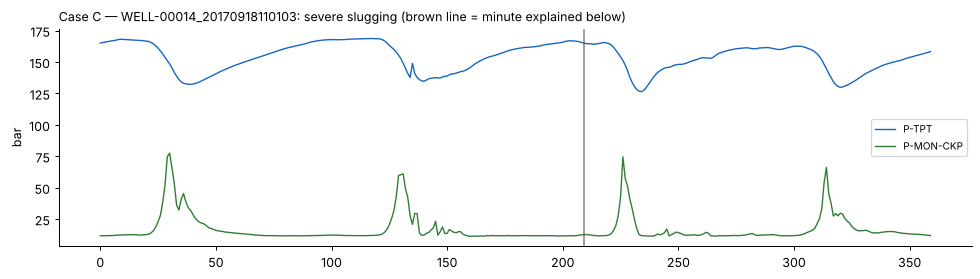

Diagnoses: [('Severe slugging', 0.99)]
Severe slugging: CF +0.99
  ← rule D-SLUG-1 "Severe slugging (large swings along the circuit)" (rule CF +0.90 × premise 0.90 = +0.81)
     because: Large, repeated swings at both the subsea tree and the choke: severe slugging is detectable along the whole production circuit.
        TPT_CYCLE = LARGE: CF +0.90
          ← rule A-TPT_CYCLE-L "Large repeated swings in p_tpt" (rule CF +0.90 × premise 1.00 = +0.90)
             because: p_tpt went up and down repeatedly in the last 2 hours with a swing above the 'large' size (10 bar for main pressures).
                • sensor fact p_tpt.cycle = LARGE (trust 1.00, reading quality OK)
        CKP_CYCLE = LARGE: CF +0.90
          ← rule A-CKP_CYCLE-L "Large repeated swings in p_mon_ckp" (rule CF +0.90 × premise 1.00 = +0.90)
             because: p_mon_ckp went up and down repeatedly in the last 2 hours with a swing above the 'large' size (10 bar for main pressures).
                • sensor fact p_mo

In [16]:
C = 'WELL-00014_20170918110103'
fc = facts_of(C); cc = clean(C)
tlC = monitor.replay(engine, fc)
alC = monitor.alarms(tlC, FAULTS, S['alarm_threshold'], S['alarm_persistence_min'])
mC = int(tlC.loc[alC['SEVERE_SLUGGING'], 'minute'].iloc[len(tlC.loc[alC['SEVERE_SLUGGING']]) // 2])
wmC = engine.forward_chain(engine.initial_memory(fc.iloc[mC].to_dict(), VARS))
fig, ax = plt.subplots(figsize=(11, 3.2))
for v, c in [('p_tpt', '#1565c0'), ('p_mon_ckp', '#2e7d32')]:
    ax.plot(cc[v], color=c, lw=1.1, label=v.upper().replace('_', '-'))
ax.axvline(mC, color='#6d4c41', lw=1.5, alpha=0.6); ax.legend(fontsize=8); ax.set_ylabel('bar')
ax.set_title(f'Case C — {C}: severe slugging (brown line = minute explained below)', loc='left', fontsize=10)
plt.tight_layout(); plt.savefig('outputs/figures/21_caseC_slugging.png', dpi=150); plt.show()
print('Diagnoses:', [(LABEL[f], round(c, 2)) for f, c in engine.diagnoses(wmC)])
print('\n'.join(explain.how(engine, wmC, 'FAULT', 'SEVERE_SLUGGING')[:14]))

In [17]:
print('\n'.join(explain.why_not(engine, wmC, 'SPURIOUS_CLOSURE_OF_DHSV')))

Why not 'Spurious closure of DHSV'?  (current CF +0.00)
  D-DHSV-1 [did not fire] Spurious DHSV closure (restriction at DHSV + flow stopping)
      ✗ needs RESTRICTION = DHSV_ZONE; have nothing (unknown)
  D-DHSV-2 [did not fire] Spurious DHSV closure (restriction at DHSV)
      ✗ needs RESTRICTION = DHSV_ZONE; have nothing (unknown)


In [18]:
decision.recommend(kb, 'SEVERE_SLUGGING', 'PRODUCTION_FIRST', wm=wmC)

,rank,id,action,for,safety_risk,production_loss,cost,effectiveness,score,status,why
0,1,A-SLUG-3,Switch on active (feedback) slug control on the production choke.,fault,1,1,3,5,0.975,allowed,Automatic choke control removes slugging with little production loss.
1,2,A-SLUG-2,Increase gas-lift injection to lighten the riser column.,fault,2,2,2,3,0.700,allowed,Keeps more production but uses more gas and may not remove slugging.
2,3,A-SLUG-1,Choke back the production choke to stabilise the flow.,fault,1,3,1,4,0.650,allowed,"Classic mitigation: more back-pressure suppresses the slug cycle, at the price of some production."
3,<NA>,A-SLUG-4,Ignore it and keep producing at full rate.,fault,4,1,1,1,NaN,BLOCKED by SC-SLUG-IGNORE,Do not keep producing through sustained severe slugging without mitigation — it stresses and can damage we...


---
## 5. Case D — hydrate in the production line: safety constraints
A hydrate plug is one of the most dangerous situations to remediate: a plug released by a pressure difference behaves like a projectile (PetroWiki/SPE). Two tempting shortcuts are in the knowledge base on purpose — the KBS must **block** them, whatever the stakeholder profile.

In [19]:
D = 'WELL-00019_20141117190526'
fd = facts_of(D)
tlD = monitor.replay(engine, fd)
alD = monitor.alarms(tlD, FAULTS, S['alarm_threshold'], S['alarm_persistence_min'])
mD = int(tlD.loc[alD['HYDRATE_IN_PRODUCTION_LINE'], 'minute'].iloc[0])
wmD = engine.forward_chain(engine.initial_memory(fd.iloc[mD].to_dict(), VARS))
print(f"Onset minute {instances.loc[D, 'onset_minute']:.0f}; hydrate alarm at minute {mD}")
print('Diagnoses:', [(LABEL[f], round(c, 2)) for f, c in engine.diagnoses(wmD)])
print('\n'.join(explain.how(engine, wmD, 'FAULT', 'HYDRATE_IN_PRODUCTION_LINE')[:16]))

Onset minute 300; hydrate alarm at minute 400
Diagnoses: [('Hydrate in production line', 0.94)]
Hydrate in production line: CF +0.94
  ← rule D-HPL-4 "Hydrate in production line (deep pressure up, tree cooling)" (rule CF +0.50 × premise 0.90 = +0.45)
     because: Pressure builds downhole while the tree cools and its pressure does not fall — blockage above the tree.
        PDG_P = UP: CF +0.90
          ← rule A-PDG_P-1 "Downhole pressure (PDG) above its normal level" (rule CF +0.90 × premise 1.00 = +0.90)
             because: Downhole pressure (PDG) is clearly above this well's own baseline (first hour).
                • sensor fact p_pdg.level = HIGH (trust 1.00, reading quality OK)
        TPT_T = DOWN: CF +0.97
          ← rule A-TPT_T-4 "Subsea tree temperature (TPT) falling" (rule CF +0.70 × premise 1.00 = +0.70)
             because: Subsea tree temperature (TPT) fell more than the normal 15-minute variation (and is not above normal — a high but settling reading is not 'down'

In [20]:
for p in kb.profiles:
    t = decision.recommend(kb, 'HYDRATE_IN_PRODUCTION_LINE', p, wm=wmD)
    print(f"\n=== {kb.profiles[p]['label']} ===")
    display(t[['rank', 'action', 'score', 'status']])


=== Safety first (HSE, well integrity) ===


,rank,action,score,status
0,1,"Depressurize the line slowly from BOTH sides of the plug, then let the hydrate dissociate.",0.700,allowed
1,2,Bring coiled tubing to place inhibitor (MEG/methanol) at the plug face.,0.537,allowed
2,<NA>,Increase hydrate-inhibitor dosing while the line still flows.,NaN,NOT APPLICABLE now
3,<NA>,Depressurize from one side only to clear the plug faster.,NaN,BLOCKED by SC-HYD-ONESIDE
4,<NA>,Heat the line at the middle of the plug.,NaN,BLOCKED by SC-HYD-HEAT



=== Production first (production manager) ===


,rank,action,score,status
0,1,Bring coiled tubing to place inhibitor (MEG/methanol) at the plug face.,0.525,allowed
1,2,"Depressurize the line slowly from BOTH sides of the plug, then let the hydrate dissociate.",0.450,allowed
2,<NA>,Increase hydrate-inhibitor dosing while the line still flows.,NaN,NOT APPLICABLE now
3,<NA>,Depressurize from one side only to clear the plug faster.,NaN,BLOCKED by SC-HYD-ONESIDE
4,<NA>,Heat the line at the middle of the plug.,NaN,BLOCKED by SC-HYD-HEAT



=== Cost first (finance) ===


,rank,action,score,status
0,1,"Depressurize the line slowly from BOTH sides of the plug, then let the hydrate dissociate.",0.700,allowed
1,2,Bring coiled tubing to place inhibitor (MEG/methanol) at the plug face.,0.237,allowed
2,<NA>,Increase hydrate-inhibitor dosing while the line still flows.,NaN,NOT APPLICABLE now
3,<NA>,Depressurize from one side only to clear the plug faster.,NaN,BLOCKED by SC-HYD-ONESIDE
4,<NA>,Heat the line at the middle of the plug.,NaN,BLOCKED by SC-HYD-HEAT


* Under **every** profile, one-sided depressurization and heating the middle of the plug are **BLOCKED** — even the Production-first profile cannot select them, although they are faster. Safety constraints are hard filters, not weights.
* Inhibitor dosing is **NOT APPLICABLE**: the flow has already stopped (the plug has formed), and PetroWiki notes inhibitor then cannot reach the plug.
* Among the remaining safe actions the **stakeholders disagree**: Safety-first and Cost-first choose slow two-sided depressurization; Production-first accepts the cost of a coiled-tubing vessel to restore flow sooner.

---
## 6. Case E — not enough trustworthy sensors
WELL-00008 has none of the key process sensors working. Instead of saying "normal" (which would be a guess), the KBS reports that it cannot decide.

In [21]:
E = 'WELL-00008_20170610210246'
fe = facts_of(E)
wmE = engine.forward_chain(engine.initial_memory(fe.iloc[len(fe) // 2].to_dict(), VARS))
print('Key sensors usable:', [v for v in S['key_sensors'] if (fe.iloc[len(fe) // 2][f'{v}_rel'] or 0) >= 0.5] or 'none')
print('Verdict:', engine.verdict(wmE))
print('\n'.join(explain.how(engine, wmE, 'STATUS', 'INSUFFICIENT_DATA')))

Key sensors usable: ['p_jus_ckgl']
Verdict: ('UNDETERMINED', 0.0)
STATUS = INSUFFICIENT_DATA: CF +1.00
  ← rule X-COVERAGE "Too few trustworthy sensors to diagnose" (rule CF +1.00 × premise 1.00 = +1.00)
     because: Fewer than 2 of the 8 key process sensors give trustworthy readings right now. Instead of guessing 'normal', the system reports that it cannot decide (incomplete information).
        • sensor fact DATA_COVERAGE = LOW (trust 1.00)


---
## 7. Conflicting stakeholder requirements
The same diagnosis leads to different best actions depending on whose priorities dominate. Safety constraints stay in force for all of them.

In [22]:
comp = pd.concat([decision.compare_profiles(kb, f).assign(fault=LABEL[f]) for f in FAULTS])
comp = comp.pivot(index='fault', columns='profile', values='top action')
comp.to_csv('outputs/tables/profile_comparison.csv')
comp

profile,Cost first (finance),Production first (production manager),"Safety first (HSE, well integrity)"
fault,,,
Abrupt increase of BSW,"Confirm with a fluid sample, then adjust choke / gas-lift to the new operating point.","Confirm with a fluid sample, then adjust choke / gas-lift to the new operating point.","Confirm with a fluid sample, then adjust choke / gas-lift to the new operating point."
Flow instability,Watch closely and make a small choke adjustment to restore stable flow.,Watch closely and make a small choke adjustment to restore stable flow.,Watch closely and make a small choke adjustment to restore stable flow.
Hydrate in production line,Increase hydrate-inhibitor dosing while the line still flows.,Increase hydrate-inhibitor dosing while the line still flows.,Increase hydrate-inhibitor dosing while the line still flows.
Hydrate in service line,Stop gas lift through the blocked line and produce without it meanwhile.,Depressurize the service line from both sides and inject inhibitor.,Stop gas lift through the blocked line and produce without it meanwhile.
Quick restriction in PCK,Check the production choke and restore it to its set-point.,Check the production choke and restore it to its set-point.,Check the production choke and restore it to its set-point.
Rapid productivity loss,Change the operating point (open choke / increase gas lift) to keep natural flow.,Change the operating point (open choke / increase gas lift) to keep natural flow.,Run a well test and update the reservoir model.
Scaling in PCK,Open the choke further to compensate.,Open the choke further to compensate.,Inject scale inhibitor upstream of the choke.
Severe slugging,Choke back the production choke to stabilise the flow.,Switch on active (feedback) slug control on the production choke.,Switch on active (feedback) slug control on the production choke.
Spurious closure of DHSV,"Equalize pressure across the DHSV, then reopen it through its hydraulic control line (corrective operating...","Equalize pressure across the DHSV, then reopen it through its hydraulic control line (corrective operating...","Equalize pressure across the DHSV, then reopen it through its hydraulic control line (corrective operating..."


---
## 8. Knowledge refinement on the development set
A knowledge base is not right the first time. The first version was tested on the **125 development instances** (never on the held-out instances used in Notebook 4), and every disagreement with Petrobras's labels was investigated. Changes were made only when they had a physical or literature justification.

| # | Problem found in the data | Change to the knowledge | Justification |
|---|---|---|---|
| 1 | A single drop-and-recovery (DHSV closure) was read as an oscillation → false *slugging* | Cycling requires ≥ 2 direction reversals in 2 h | Slugging is *periodic* (Vargas 2019) |
| 2 | A low-but-recovering pressure was read as "pressure up" → false *hydrate* | A rising trend counts as UP only if the level is not below normal | Level vs trend distinction |
| 3 | The DHSV **status signal** shows "closed" in only 14 of ~1,500 minutes of real spurious closures, yet often in normal operation | Rules using that signal were **removed** | Thesis: spurious closures happen "without any surface indication" |
| 4 | Wells with almost no sensors were called "normal" | New verdict **UNDETERMINED** when < 2 key sensors are trustworthy | Incomplete information must not be hidden |
| 5 | 43 *hydrate in service line* instances contain **no abnormal label** at all | Flagged as label-inconsistent; reported separately | Data-quality finding |
| 6 | During slugging, nearly every location rule fired | Location rules blocked while flow oscillates | Flow physics |
| 7 | Shut-ins, restarts and depressurizations caused false alarms | Operation-context meta-rules | Operations change pressures on purpose; depressurization is hydrate remediation (PetroWiki) |
| 8 | Scaling develops too slowly for 15-min trends | New 3-hour **drift** facts and slow-scaling rules | Experts use 72-h windows for scaling (Vargas 2019) |
| 9 | Spiky downhole gauge triggered "oscillating flow" | PDG excluded from the oscillation check | PDGs commonly fail (Vargas 2019) |
| 10 | Wells without PDG and choke sensors could not show a DHSV closure | Tree-only DHSV rule (sudden drop + cooling) | Flow physics |
| 11 | Tested: data-driven CF adjustment (CF = ½ expert + ½ measured precision) | **Rejected** — accuracy fell from 49.6% to 42.7% | Lowered all CFs uniformly; structural fixes worked better |
| 12 | Alarm settings | Threshold 0.6, persistence 5 min, verdict = longest alarm | Grid search on development set; "first alarm" rule rejected (slugging needs 2 h of history) |

Measured precision of each diagnosis rule on the development set (the evidence behind items 6–11):

In [23]:
stats = __import__('wellsense').refine.rule_statistics(InferenceEngine(kb, keep_trace=False), pd.read_sql('SELECT * FROM facts', con), instances)
stats['rule name'] = stats['rule'].map(lambda r: kb.rule_by_id[r].name)
stats.to_csv('outputs/tables/rule_precision_dev.csv', index=False)
stats.sort_values(['fault', 'precision'], ascending=[True, False])[['rule', 'rule name', 'instances', 'precision', 'expert_cf']].round(2)

,rule,rule name,instances,precision,expert_cf
0,D-BSW-1,"Abrupt BSW increase (surface pressure down, temperatures up)",19,0.16,0.70
2,D-BSW-3,"Abrupt BSW increase (gradual surface pressure decline, flow continues)",17,0.12,0.45
1,D-BSW-2,"Abrupt BSW increase (deep pressure up, surface down, temperatures up)",3,0.00,0.80
12,D-INST-1,Flow instability (small swings at subsea tree),14,0.50,0.60
13,D-INST-2,Flow instability (small swings at tree and choke),14,0.50,0.75
14,D-INST-3,Flow instability (small swings before choke),46,0.26,0.35
8,D-HPL-4,"Hydrate in production line (deep pressure up, tree cooling)",13,0.38,0.50
5,D-HPL-1,Hydrate in production line (restriction in line + flow stopping),12,0.25,0.85
7,D-HPL-3,Hydrate in production line (hydrate conditions + restriction),12,0.25,0.80
6,D-HPL-2,Hydrate in production line (restriction in line),25,0.19,0.60


### Development-set performance of the final knowledge base

In [24]:
dev = evaluate.run(InferenceEngine(kb, keep_trace=False), 'db/wellsense.db', list(instances.index), instances, progress_every=0)
dev.to_csv('outputs/tables/dev_results.csv', index=False)
display(evaluate.scores(dev).round(3).to_frame('development set'))
r = dev[dev.labels_consistent]
pd.crosstab(r['true'].map(LABEL), r['predicted'].map(lambda p: LABEL.get(p, p)))

,development set
instances,117.000
accuracy,0.496
balanced_accuracy,0.459
event_detection_rate,0.657
false_alarm_rate_normal_wells,0.067
alarm_during_labelled_normal_minutes,0.094
undetermined_rate,0.009
median_detection_delay_min,36.000


predicted,Abrupt increase of BSW,Flow instability,Hydrate in production line,Hydrate in service line,NORMAL,Rapid productivity loss,Scaling in PCK,Severe slugging,Spurious closure of DHSV
true,,,,,,,,,
Abrupt increase of BSW,1,0,0,0,2,1,0,0,0
Flow instability,0,7,0,0,8,0,0,0,0
Hydrate in production line,0,0,3,1,5,0,3,2,0
Hydrate in service line,0,0,0,5,0,0,1,1,0
Quick restriction in PCK,0,0,0,0,5,0,1,0,0
Rapid productivity loss,0,0,0,0,0,6,0,3,2
Scaling in PCK,0,0,0,1,12,0,2,0,0
Severe slugging,0,2,0,0,0,0,0,13,0
Spurious closure of DHSV,0,0,0,0,3,3,0,1,8


---
## 9. Live consultation prototype — "this is what I see, what is wrong and what should I do?"
Sections 2–6 diagnosed **recorded** sensor data. Here an engineer **describes the situation in their own words** (from simple menus) and the **same knowledge base and the same inference engine** do the rest:

1. **Your observations become facts** — e.g. *"Subsea tree pressure: dropped suddenly"* → `p_tpt.level = LOW`, `p_tpt.trend = FALLING`, `p_tpt.jump30 = JUMP_DOWN`. *How sure are you?* sets their certainty (Sure 1.0 · Fairly sure 0.8 · Not sure 0.5). Sensors you leave on *Don't know* stay **unknown** (incomplete information).
2. **Forward chaining** fires the 153 rules: symptoms → where the blockage is → which fault.
3. **Backward chaining**: if the leading fault is uncertain (CF between 0.3 and 0.8) the KBS **asks you questions**, saying **why**.
4. **Explanation**: HOW the conclusion was reached, and WHY NOT the runner-up.
5. **Decision support**: fault priority (severity), and maintenance actions ranked for the chosen stakeholder profile — scored on safety risk, production loss (downtime), cost and effectiveness — with **unsafe actions BLOCKED** and actions that would not work **NOT APPLICABLE**.

**How to use it in Colab:** run the next cell, set the menus (or load a ready-made example at the top) and click **🔍 Diagnose**. When the KBS is unsure it asks a question with **clickable answers** (Yes / No / Don't know); click one and it continues. Change any menu and click Diagnose again. Nothing in the rest of the notebook waits for you.

In [25]:
OBS_SENSORS = [('p_pdg', 'Downhole pressure (PDG)'),
               ('p_tpt', 'Subsea tree pressure (TPT)'),
               ('t_tpt', 'Subsea tree temperature (TPT)'),
               ('p_mon_ckp', 'Pressure before the production choke'),
               ('t_jus_ckp', 'Temperature after the production choke'),
               ('p_jus_ckgl', 'Gas-lift line pressure'),
               ('qgl', 'Gas-lift flow rate'),
               ('p_anular', 'Annulus pressure')]
SENSOR_NAME = dict(OBS_SENSORS)

_STEADY = dict(level='NORMAL', trend='STABLE', osc='STEADY', step='NONE', drift='STABLE', cycle='NONE', jump30='NONE')
BEHAVIOUR = {                                             # plain-language observation → symbolic facts (as the ETL makes them)
    "Don't know / no sensor": None,
    'Normal': {},
    'Went up': dict(level='HIGH', trend='RISING'),
    'Jumped up suddenly': dict(level='HIGH', trend='RISING', step='JUMP_UP', jump30='JUMP_UP'),
    'Went down': dict(level='LOW', trend='FALLING'),
    'Dropped suddenly': dict(level='LOW', trend='FALLING', step='JUMP_DOWN', jump30='JUMP_DOWN'),
    'Creeping up slowly (over hours)': dict(drift='RISING'),
    'Creeping down slowly (over hours)': dict(drift='FALLING'),
    'Big swings up and down': dict(osc='OSCILLATING', cycle='LARGE'),
    'Small wobbles': dict(osc='OSCILLATING', cycle='SMALL'),
    'Stuck at one value (frozen)': 'FROZEN',
}
CONFIDENCE = {'Sure': 1.0, 'Fairly sure': 0.8, 'Not sure': 0.5}
WELL_STATE = {"Don't know": None, 'Producing (open)': 'Open', 'Shut in': 'Shut-In', 'Restarting': 'Restart',
              'Intervention (flushing / bullheading)': 'Flushing Diesel'}
GAS_LIFT = {"Don't know": None, 'On': 'ON', 'Off': 'OFF'}
CHOKE = {"Don't know": None, 'Unchanged': 'STABLE', 'Being closed': 'CLOSING', 'Being opened': 'OPENING'}
PROFILE_OF = {spec['label']: p for p, spec in kb.profiles.items()}
ALTERNATIVE = {   # the most natural "why not this one instead?" for each fault (similar symptoms)
    'SPURIOUS_CLOSURE_OF_DHSV': 'HYDRATE_IN_PRODUCTION_LINE', 'HYDRATE_IN_PRODUCTION_LINE': 'SPURIOUS_CLOSURE_OF_DHSV',
    'SEVERE_SLUGGING': 'FLOW_INSTABILITY', 'FLOW_INSTABILITY': 'SEVERE_SLUGGING',
    'SCALING_IN_PCK': 'QUICK_RESTRICTION_IN_PCK', 'QUICK_RESTRICTION_IN_PCK': 'SCALING_IN_PCK',
    'HYDRATE_IN_SERVICE_LINE': 'HYDRATE_IN_PRODUCTION_LINE', 'ABRUPT_INCREASE_OF_BSW': 'RAPID_PRODUCTIVITY_LOSS',
    'RAPID_PRODUCTIVITY_LOSS': 'ABRUPT_INCREASE_OF_BSW'}
FAULT_OF = {LABEL[f]: f for f in FAULTS}

EXAMPLES = {   # ready-made situations for a quick demo: (observations, context, scripted operator answers)
    'Safety valve closed by itself?': (
        {'p_pdg': 'Went up', 'p_tpt': 'Dropped suddenly', 't_tpt': 'Went down', 'p_mon_ckp': 'Went down'},
        {'confidence': 'Fairly sure', 'well': 'Producing (open)', 'gas_lift': 'On', 'choke': 'Unchanged'},
        {'Q_DHSV_COMMANDED': 'NO', 'Q_DHSV_HYDRAULICS': 'YES'}),
    'Pressure swinging hard': (
        {'p_tpt': 'Big swings up and down', 'p_mon_ckp': 'Big swings up and down', 't_tpt': 'Normal'},
        {'confidence': 'Sure', 'well': 'Producing (open)', 'gas_lift': 'On', 'choke': 'Unchanged'},
        {'Q_SEPARATOR_SURGES': 'YES'}),
    'Line blocked after a restart': (
        {'p_pdg': 'Went up', 'p_tpt': 'Went up', 't_tpt': 'Went down', 'p_mon_ckp': 'Went down'},
        {'confidence': 'Fairly sure', 'well': 'Restarting', 'gas_lift': 'On', 'choke': 'Unchanged'},
        {'Q_HYDRATE_CURVE': 'YES', 'Q_RECENT_RESTART': 'YES'}),
    'Choke pressure creeping up': (
        {'p_mon_ckp': 'Creeping up slowly (over hours)', 't_jus_ckp': 'Creeping down slowly (over hours)', 'p_tpt': 'Normal'},
        {'confidence': 'Fairly sure', 'well': 'Producing (open)', 'gas_lift': 'On', 'choke': 'Unchanged'},
        {'Q_CHOKE_LOCAL': 'NO', 'Q_SCALE_HISTORY': 'YES'}),
    'Gas-lift line blocked': (
        {'p_jus_ckgl': 'Went up', 'qgl': 'Went down', 'p_tpt': 'Normal'},
        {'confidence': 'Fairly sure', 'well': 'Producing (open)', 'gas_lift': 'On', 'choke': 'Unchanged'},
        {'Q_HYDRATE_CURVE': 'YES', 'Q_SERVICE_LINE_INHIBITOR': 'YES'}),
    'Frozen downhole gauge': (
        {'p_pdg': 'Stuck at one value (frozen)', 'p_tpt': 'Dropped suddenly', 't_tpt': 'Went down'},
        {'confidence': 'Sure', 'well': 'Producing (open)', 'gas_lift': 'On', 'choke': "Don't know"},
        {'Q_DHSV_COMMANDED': 'NO', 'Q_DHSV_HYDRAULICS': 'YES'}),
    'Only one sensor known': (
        {'p_tpt': 'Went down'},
        {'confidence': 'Sure', 'well': "Don't know", 'gas_lift': "Don't know", 'choke': "Don't know"},
        {}),
}


def observations_to_row(obs, ctx):
    """Turn menu choices into one row shaped exactly like the ETL 'facts' table."""
    trust = CONFIDENCE[ctx.get('confidence', 'Sure')]
    row = {}
    for v, _ in OBS_SENSORS:
        b = BEHAVIOUR[obs.get(v, "Don't know / no sensor")]
        if b is None:
            row[f'{v}_rel'] = 0.0                          # unknown → never enters working memory
            continue
        facts = dict(_STEADY, **({} if b == 'FROZEN' else b))
        row.update({f'{v}_{k}': x for k, x in facts.items()})
        row[f'{v}_rel'] = 0.2 if b == 'FROZEN' else trust  # a frozen gauge is barely trusted, as in the ETL
        row[f'{v}_q'] = 'FROZEN' if b == 'FROZEN' else 'OK'
    row['well_state'] = WELL_STATE[ctx.get('well', "Don't know")]
    row['gas_lift'] = GAS_LIFT[ctx.get('gas_lift', "Don't know")]
    row['aber_ckp_trend'] = CHOKE[ctx.get('choke', "Don't know")]
    return row


def _reported(lines):
    return [l.replace('• sensor fact', '• you reported').replace(', reading quality OK', '') for l in lines]


def start_consultation(obs, ctx):
    """Observations → working memory → forward chaining. Prints what was told and the first diagnosis."""
    eng = InferenceEngine(kb)
    print('WHAT YOU TOLD ME')
    for v, b in obs.items():
        if b != "Don't know / no sensor":
            print(f'  • {SENSOR_NAME[v]}: {b}')
    print(f"  • Well: {ctx.get('well')} · gas lift: {ctx.get('gas_lift')} · choke: {ctx.get('choke')} · "
          f"how sure: {ctx.get('confidence')}")
    wm = eng.forward_chain(eng.initial_memory(observations_to_row(obs, ctx), VARS))
    first = eng.diagnoses(wm)
    print('\nFIRST DIAGNOSIS (from your observations only)')
    print('  ' + (', '.join(f"{LABEL[f]} {c:.2f}" for f, c in first[:3]) or 'no fault suggested'))
    return eng, wm


def report(eng, wm, profile_label='Safety first (HSE, well integrity)', why_not=None):
    """Verdict, priority, HOW / WHY-NOT explanation and stakeholder-aware, safety-checked actions."""
    dx = eng.diagnoses(wm)
    verdict, vcf = eng.verdict(wm)
    alerts = [v for (f, v), c in wm.facts.items() if f == 'SENSOR_ALERT' and c > 0]
    print('\n' + '=' * 90)
    if verdict == 'UNDETERMINED':
        print('VERDICT: UNDETERMINED — fewer than 2 of the 8 key sensors are known, so I will not guess.')
        print('         Tell me about at least one more key sensor (pressures, temperatures, gas lift, annulus).')
    elif verdict == 'NORMAL':
        print('VERDICT: no fault reaches the alarm level (CF ≥ 0.6).')
        if dx:
            print('         Possible, but not confirmed: ' + ', '.join(f"{LABEL[f]} {c:.2f}" for f, c in dx[:3]))
    else:
        print(f"VERDICT: {LABEL[verdict]}  (CF {vcf:.2f})  ✅ ALARM   ·   priority: severity {kb.faults[verdict]['severity']} of 5")
        print(f"         {kb.faults[verdict]['description']}")
        if len(dx) > 1:
            print('         Other possibilities: ' + ', '.join(f"{LABEL[f]} {c:.2f}" for f, c in dx[1:3]))
    if alerts:
        print('SENSOR ALERT: ' + ', '.join(alerts) + ' — that gauge is discounted and flagged for maintenance.')
    print('=' * 90)
    if verdict not in kb.faults:
        if why_not:
            print('\n' + '\n'.join(explain.why_not(eng, wm, why_not)[:8]))
        return
    print('\nHOW I reached this conclusion')
    print('\n'.join(_reported(explain.how(eng, wm, 'FAULT', verdict, max_depth=6))))
    other = why_not or ALTERNATIVE.get(verdict)
    if other and other != verdict:
        print('\n' + '\n'.join(explain.why_not(eng, wm, other)[:8]))
    t = decision.recommend(kb, verdict, PROFILE_OF[profile_label], sensor_alerts=alerts, wm=wm)
    print(f"\nRECOMMENDED ACTIONS — profile: {profile_label}")
    print('  (scores 1–5: safety risk · production loss/downtime · cost · effectiveness)')
    for _, a in t.iterrows():
        head = f"  {int(a['rank'])}." if pd.notna(a['rank']) else '  ✖ '
        score = f"✅ allowed, score {a['score']:.2f}" if pd.notna(a['score']) else a['status']
        print(f"{head} {a['action']}")
        print(f"      [{a['for']}] risk {a['safety_risk']} · loss {a['production_loss']} · cost {a['cost']} · "
              f"effect {a['effectiveness']}  →  {score}")
        print(f"      why: {a['why']}")


def consultation(obs, ctx, profile_label='Safety first (HSE, well integrity)', answers=None, why_not=None):
    """The whole consultation in one call (questions answered from `answers`, else "don't know")."""
    eng, wm = start_consultation(obs, ctx)

    def ask(q, why):
        a = (answers or {}).get(q['id'], 'UNKNOWN')
        print(f"\n❓ {q['text']}  [{q['who']}]\n   WHY am I asking? {why}\n   Answer: {a if a != 'UNKNOWN' else 'don’t know'}")
        return a

    eng.consult(wm, ask)
    report(eng, wm, profile_label, why_not)
    return wm

In [26]:
# ▶ Run this cell: the menus appear. Set them (or load an example) and click 🔍 Diagnose. Click again after any change.
CONTROLS = {}
try:
    import ipywidgets as W
    from IPython.display import display
    _w, _s = {'width': '560px'}, {'description_width': '270px'}
    CONTROLS['example'] = W.Dropdown(options=['(set the menus yourself)'] + list(EXAMPLES), value='Safety valve closed by itself?',
                                     description='Load an example:', layout=_w, style=_s)
    for v, name in OBS_SENSORS:
        CONTROLS[v] = W.Dropdown(options=list(BEHAVIOUR), value="Don't know / no sensor", description=name + ':', layout=_w, style=_s)
    CONTROLS['confidence'] = W.Dropdown(options=list(CONFIDENCE), description='How sure are you?', layout=_w, style=_s)
    CONTROLS['well'] = W.Dropdown(options=list(WELL_STATE), description='What is the well doing?', layout=_w, style=_s)
    CONTROLS['gas_lift'] = W.Dropdown(options=list(GAS_LIFT), description='Gas lift:', layout=_w, style=_s)
    CONTROLS['choke'] = W.Dropdown(options=list(CHOKE), description='Production choke opening:', layout=_w, style=_s)
    CONTROLS['profile'] = W.Dropdown(options=list(PROFILE_OF), description='Who decides (stakeholder profile)?', layout=_w, style=_s)
    CONTROLS['why_not'] = W.Dropdown(options=['(automatic)'] + list(FAULT_OF), description='Also explain: why not…', layout=_w, style=_s)

    def load_example(change=None):
        name = CONTROLS['example'].value
        if name in EXAMPLES:
            obs, ctx, _ = EXAMPLES[name]
            for v, _ in OBS_SENSORS:
                CONTROLS[v].value = obs.get(v, "Don't know / no sensor")
            for k in ('confidence', 'well', 'gas_lift', 'choke'):
                CONTROLS[k].value = ctx[k]
    CONTROLS['example'].observe(load_example, names='value')
    load_example()

    diagnose_btn = W.Button(description='Diagnose', icon='search', button_style='primary', layout={'width': '200px'})
    out = W.Output()
    LIVE = {}

    def next_step():
        """Backward chaining, one question at a time: show it with clickable answers, or finish."""
        nq = LIVE['eng'].next_question(LIVE['wm']) if LIVE['asked'] < 4 else None
        if nq is None:
            with out:
                report(LIVE['eng'], LIVE['wm'], CONTROLS['profile'].value, FAULT_OF.get(CONTROLS['why_not'].value))
            return
        qid, goal, why = nq
        q = kb.questions[qid]
        buttons = [W.Button(description=a.capitalize()) for a in q['answers']] + [W.Button(description="Don't know")]

        def answer(btn):
            for b in buttons:
                b.disabled = True
            a = btn.description.upper() if btn.description != "Don't know" else 'UNKNOWN'
            LIVE['wm'].asked[qid] = (a, why)
            LIVE['asked'] += 1
            if a in q['answers']:
                LIVE['wm'].assert_fact(qid, a, 1.0, origin='user')
            LIVE['eng'].forward_chain(LIVE['wm'])
            with out:
                print(f"   Your answer: {btn.description}")
            next_step()

        for b in buttons:
            b.on_click(answer)
        with out:
            print(f"\n❓ {q['text']}  [{q['who']}]")
            print(f"   WHY am I asking? {why}")
            display(W.HBox(buttons))

    def on_diagnose(_):
        out.clear_output()
        obs = {v: CONTROLS[v].value for v, _ in OBS_SENSORS}
        ctx = {k: CONTROLS[k].value for k in ('confidence', 'well', 'gas_lift', 'choke')}
        with out:
            LIVE['eng'], LIVE['wm'] = start_consultation(obs, ctx)
        LIVE['asked'] = 0
        next_step()

    diagnose_btn.on_click(on_diagnose)
    display(W.VBox([W.HTML('<h3>🛢️ WellSense consultation — what are you seeing?</h3>')] + list(CONTROLS.values())
                   + [diagnose_btn, out]))
except ImportError:
    print('ipywidgets is not available here — in Colab the menus and the Diagnose button appear. Example without menus:\n')
    o, c, a = EXAMPLES['Safety valve closed by itself?']
    consultation(o, c, answers=a)

(In Colab, the menus and the 🔍 Diagnose button appear here. Below is the same consultation run without menus, for reference.)

WHAT YOU TOLD ME
  • Downhole pressure (PDG): Went up
  • Subsea tree pressure (TPT): Dropped suddenly
  • Subsea tree temperature (TPT): Went down
  • Pressure before the production choke: Went down
  • Well: Producing (open) · gas lift: On · choke: Unchanged · how sure: Fairly sure

FIRST DIAGNOSIS (from your observations only)
  Spurious closure of DHSV 0.75

❓ Was the DHSV closed on purpose (shutdown or ESD command) in the last hour?  [Control-room operator]
   WHY am I asking? I suspect 'Spurious closure of DHSV' (CF 0.75) but cannot confirm it from the sensors. Answer NO raises it (Q-DHSV-NO: Nobody commanded the closure, so it was spurious.); answer YES lowers it (Q-DHSV-YES: The closure was commanded on purpose — expected, not a fault.)
   Answer: NO

VERDICT: Spurious closure of DHSV  (CF 0.84)  ✅ ALARM   ·   priority: severity 4 of 5
         The down

### 9.1 More situations, without the menus
The same function can be called directly. Two contrasting cases: a **frozen gauge** (the KBS flags it and reasons with the other sensors) and **only one sensor known** (the KBS refuses to guess).

In [27]:
for name in ['Frozen downhole gauge', 'Only one sensor known']:
    print('#' * 100 + f'\n# EXAMPLE: {name}\n' + '#' * 100)
    o, c, a = EXAMPLES[name]
    consultation(o, c, 'Production first (production manager)', answers=a)
    print()

####################################################################################################
# EXAMPLE: Frozen downhole gauge
####################################################################################################
WHAT YOU TOLD ME
  • Downhole pressure (PDG): Stuck at one value (frozen)
  • Subsea tree pressure (TPT): Dropped suddenly
  • Subsea tree temperature (TPT): Went down
  • Well: Producing (open) · gas lift: On · choke: Don't know · how sure: Sure

FIRST DIAGNOSIS (from your observations only)
  Spurious closure of DHSV 0.47

❓ Was the DHSV closed on purpose (shutdown or ESD command) in the last hour?  [Control-room operator]
   WHY am I asking? I suspect 'Spurious closure of DHSV' (CF 0.47) but cannot confirm it from the sensors. Answer NO raises it (Q-DHSV-NO: Nobody commanded the closure, so it was spurious.); answer YES lowers it (Q-DHSV-YES: The closure was commanded on purpose — expected, not a fault.)
   Answer: NO

❓ Is the DHSV hydraulic control-l

In [28]:
con.close()
print('Next: Notebook 4 — evaluation on the 994 held-out instances.')

Next: Notebook 4 — evaluation on the 994 held-out instances.
